# Criteo: conversão por impressão com boosting e onde gastar a verba

```

Criteo: prever a conversão de cada impressão com boosting e decidir onde gastar

Pergunta do projeto: onde colocar o próximo real de mídia? A POC 1 agregou a base
Criteo por campanha e hora e perdeu o detalhe de cada impressão. Aqui o modelo
trabalha impressão por impressão, que é como a Criteo e o Google decidem a compra
de mídia na prática.

Abordagem supervisionada (classificação):
  unidade   = uma impressão (um anúncio exibido para um usuário)
  alvo      = attribution: a impressão gerou uma conversão atribuída à Criteo?
  variáveis = só o que se sabe NO MOMENTO da exibição: campanha, cat1 a cat9
              (contexto da exibição, anonimizado pela Criteo), hora do dia,
              histórico de cliques e de impressões do usuário

Fora do modelo, para não haver vazamento (são informações de DEPOIS da exibição):
  click, conversion, conversion_timestamp, conversion_id, click_pos, click_nb, cpo.
  O cost também fica fora como variável: impressões clicadas custam quase 3x mais,
  então o custo carrega informação do clique. Ele entra só na curva de custo.

Modelos comparados:
  Baselines: taxa média geral; taxa média da campanha
  Linear:    Regressão Logística
  Boosting:  Gradient Boosting do scikit-learn, XGBoost, LightGBM, CatBoost
             (os três últimos rodam se a biblioteca estiver instalada:
              pip install xgboost lightgbm catboost shap)

Validação temporal (sem embaralhar):
  treino = dias 0 a 5, validação = dia 6 (escolha do modelo e parada antecipada),
  teste = dias 7 e 8 (só para o resultado final)

Resultado de negócio: ordenando as impressões por CONVERSÃO PREVISTA POR REAL GASTO,
quanto do orçamento é preciso para capturar cada parcela das conversões? E quanto
custa a próxima conversão em cada faixa de orçamento (custo médio x custo incremental)?

Entrada: DATA_DIR/criteo_amostra_1milhao.csv (1 em cada 5 linhas da base de 5 milhões)

Saídas:
  reports/tables/criteo_comparacao_modelos.csv
  reports/tables/criteo_importancia_variaveis.csv
  reports/tables/criteo_custo_medio_vs_incremental.csv
  reports/figures/criteo_comparacao_modelos.png
  reports/figures/criteo_calibracao.png
  reports/figures/criteo_importancia_variaveis.png
  reports/figures/criteo_curva_custo_conversoes.png
  reports/figures/criteo_shap.png (se o shap estiver instalado)
```

## Imports

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

# Bibliotecas de boosting opcionais: se faltar alguma, o notebook segue com as outras
try:
    import xgboost as xgb
except ImportError:
    xgb = None
try:
    import lightgbm as lgb
except ImportError:
    lgb = None
try:
    import catboost as cb
except ImportError:
    cb = None
try:
    import shap
except ImportError:
    shap = None

print("XGBoost:", xgb.__version__ if xgb else "não instalado")
print("LightGBM:", lgb.__version__ if lgb else "não instalado")
print("CatBoost:", cb.__version__ if cb else "não instalado")
print("SHAP:", shap.__version__ if shap else "não instalado")

XGBoost: 3.4.1
LightGBM: 4.7.0
CatBoost: 1.2.10
SHAP: 0.54.1


## Parâmetros

In [2]:
ARQUIVO_CRITEO = "criteo_amostra_1milhao.csv"
SEMENTE = 42

ALVO = "attribution"
DIAS_TREINO = range(0, 6)       # dias 0 a 5
DIA_VALIDACAO = 6
DIAS_TESTE = range(7, 9)        # dias 7 e 8

MIN_OCORRENCIAS_CATEGORIA = 50  # categorias mais raras que isso viram "rara"
PARADA_ANTECIPADA = 50          # rodadas sem melhora na validação até parar
N_AMOSTRA_IMPORTANCIA = 30_000

# Colunas que só existem DEPOIS da exibição: nunca entram no modelo
COLUNAS_PROIBIDAS = ["click", "conversion", "conversion_timestamp", "conversion_id",
                     "click_pos", "click_nb", "cpo", "attribution", "cost"]

## Caminhos

In [3]:
# No notebook não existe __file__: o projeto é a pasta acima de notebooks/
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_DIR / ".env")

caminho_dados = os.getenv("DATA_DIR")
if caminho_dados is None:
    raise ValueError("A variável DATA_DIR não foi encontrada. Confira o arquivo .env.")

ARQUIVO = Path(caminho_dados) / os.getenv("CRITEO_FILE", ARQUIVO_CRITEO)
if not ARQUIVO.exists():
    raise FileNotFoundError(f"{ARQUIVO.name} não encontrado na pasta DATA_DIR.")

TABLES_DIR = PROJECT_DIR / "reports" / "tables"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Leitura

In [4]:
dados = pd.read_csv(ARQUIVO).sort_values("timestamp").reset_index(drop=True)
dados["dia"] = dados["timestamp"] // 86_400

print("Impressões:", len(dados))
print(f"Período: dia {dados['dia'].min()} a dia {dados['dia'].max()}")
print("Campanhas:", dados["campaign"].nunique(), "| Usuários:", dados["uid"].nunique())
print(f"Taxa de conversão atribuída: {dados[ALVO].mean():.2%}")
print(f"Taxa de clique: {dados['click'].mean():.2%}")
print("Conversões atribuídas sem clique:", int(((dados[ALVO] == 1) & (dados["click"] == 0)).sum()))

Impressões: 1000000
Período: dia 0 a dia 8
Campanhas: 673 | Usuários: 813155
Taxa de conversão atribuída: 2.65%
Taxa de clique: 34.79%
Conversões atribuídas sem clique: 0


## Variáveis (só o que se sabe no momento da exibição)

In [5]:
# Hora do dia (o timestamp começa em 0; o fuso não é informado, mas o ciclo diário existe)
dados["hora"] = (dados["timestamp"] % 86_400) // 3_600

# Histórico de cliques do usuário: time_since_last_click = -1 quando nunca clicou
dados["clicou_antes"] = (dados["time_since_last_click"] >= 0).astype(int)
dados["horas_desde_ultimo_clique"] = np.where(
    dados["time_since_last_click"] >= 0, dados["time_since_last_click"] / 3_600, np.nan
)

# Quantas vezes o usuário já tinha visto anúncios (contando só o passado, em ordem de tempo).
# Como a amostra tem 1 em cada 5 impressões, é uma contagem parcial, mas igual no treino e no teste.
dados["impressoes_anteriores_usuario"] = dados.groupby("uid").cumcount()
dados["impressoes_anteriores_usuario_campanha"] = dados.groupby(["uid", "campaign"]).cumcount()

CATEGORICAS = ["campaign"] + [f"cat{i}" for i in range(1, 10)]
NUMERICAS = ["hora", "clicou_antes", "horas_desde_ultimo_clique",
             "impressoes_anteriores_usuario", "impressoes_anteriores_usuario_campanha"]
VARIAVEIS = CATEGORICAS + NUMERICAS

assert not set(VARIAVEIS) & set(COLUNAS_PROIBIDAS), "Variável proibida entrou no modelo!"

## Divisão temporal

In [6]:
treino = dados[dados["dia"].isin(DIAS_TREINO)].copy()
validacao = dados[dados["dia"] == DIA_VALIDACAO].copy()
teste = dados[dados["dia"].isin(DIAS_TESTE)].copy()

# Categorias raras (menos de MIN_OCORRENCIAS no treino) viram -1 = "rara"
for coluna in CATEGORICAS:
    frequentes = treino[coluna].value_counts()
    frequentes = set(frequentes[frequentes >= MIN_OCORRENCIAS_CATEGORIA].index)
    for parte in (treino, validacao, teste):
        parte[coluna] = parte[coluna].where(parte[coluna].isin(frequentes), -1)

print("Impressões - treino:", len(treino), "| validação:", len(validacao), "| teste:", len(teste))
print(f"Taxa de conversão atribuída - treino: {treino[ALVO].mean():.2%} | teste: {teste[ALVO].mean():.2%}")
print("\nCategorias por variável (depois de agrupar as raras):")
print(treino[CATEGORICAS].nunique().to_string())

y_treino, y_val, y_teste = treino[ALVO].to_numpy(), validacao[ALVO].to_numpy(), teste[ALVO].to_numpy()

Impressões - treino: 677216 | validação: 116196 | teste: 206588
Taxa de conversão atribuída - treino: 2.66% | teste: 2.68%

Categorias por variável (depois de agrupar as raras):
campaign     643
cat1           9
cat2          40
cat3        1140
cat4          12
cat5          49
cat6          29
cat7        1640
cat8          11
cat9          30


## Funções de avaliação

In [7]:
def metricas(nome, y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "modelo": nome,
        "AUC": roc_auc_score(y, p),
        "PR_AUC": average_precision_score(y, p),
        "log_loss": log_loss(y, p),
        "brier": brier_score_loss(y, p),
    }


previsoes_val, previsoes_teste, tempos = {}, {}, {}


def registrar(nome, prever, inicio):
    """Guarda as previsões de validação e teste de um modelo já treinado."""
    previsoes_val[nome] = prever(validacao)
    previsoes_teste[nome] = prever(teste)
    tempos[nome] = time.time() - inicio
    m = metricas(nome, y_val, previsoes_val[nome])
    print(f"{nome:28s} AUC validação {m['AUC']:.4f} | tempo {tempos[nome]:.0f}s")

## Codificador de categorias pela taxa de conversão

In [8]:
def taxa_por_categoria():
    """TargetEncoder reprodutível nas versões antigas e novas do scikit-learn."""
    try:
        return TargetEncoder(target_type="binary", cv=KFold(5, shuffle=True, random_state=SEMENTE))   # sklearn >= 1.9
    except TypeError:
        return TargetEncoder(target_type="binary", random_state=SEMENTE)                              # sklearn 1.3 a 1.8

## Baselines

In [9]:
inicio = time.time()
taxa_geral = y_treino.mean()
registrar("Baseline - taxa geral", lambda df: np.full(len(df), taxa_geral), inicio)

# Taxa da campanha suavizada: campanha com poucas impressões fica perto da taxa geral
inicio = time.time()
por_campanha = treino.groupby("campaign")[ALVO].agg(["sum", "count"])
taxa_campanha = (por_campanha["sum"] + 50 * taxa_geral) / (por_campanha["count"] + 50)
registrar("Baseline - taxa da campanha",
          lambda df: df["campaign"].map(taxa_campanha).fillna(taxa_geral).to_numpy(), inicio)

Baseline - taxa geral        AUC validação 0.5000 | tempo 0s
Baseline - taxa da campanha  AUC validação 0.7757 | tempo 0s


## Regressão logística

In [10]:
# Categorias com muitos valores (campanha, cat3, cat7) viram a taxa média de conversão
# da categoria (TargetEncoder, com validação cruzada interna); as demais viram colunas 0/1
ALTA_CARDINALIDADE = ["campaign", "cat3", "cat7"]
BAIXA_CARDINALIDADE = [c for c in CATEGORICAS if c not in ALTA_CARDINALIDADE]

inicio = time.time()
logistica = make_pipeline(
    ColumnTransformer([
        ("taxa", taxa_por_categoria(), ALTA_CARDINALIDADE),
        ("zero_um", OneHotEncoder(handle_unknown="ignore", min_frequency=MIN_OCORRENCIAS_CATEGORIA), BAIXA_CARDINALIDADE),
        ("num", make_pipeline(SimpleImputer(strategy="constant", fill_value=-1), StandardScaler()), NUMERICAS),
    ]),
    LogisticRegression(max_iter=2000),
)
logistica.fit(treino[VARIAVEIS], y_treino)
registrar("Regressão Logística", lambda df: logistica.predict_proba(df[VARIAVEIS])[:, 1], inicio)

Regressão Logística          AUC validação 0.8433 | tempo 5s


## Boosting 1 - gradient boosting do scikit-learn

In [11]:
inicio = time.time()
mascara_categorica = [False] * len(ALTA_CARDINALIDADE) + [True] * len(BAIXA_CARDINALIDADE) + [False] * len(NUMERICAS)
hgb = make_pipeline(
    ColumnTransformer([
        ("taxa", taxa_por_categoria(), ALTA_CARDINALIDADE),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), BAIXA_CARDINALIDADE),
        ("num", "passthrough", NUMERICAS),
    ]),
    HistGradientBoostingClassifier(
        max_iter=1000, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=100,
        l2_regularization=1.0, categorical_features=mascara_categorica,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=PARADA_ANTECIPADA,
        random_state=SEMENTE,
    ),
)
hgb.fit(treino[VARIAVEIS], y_treino)
registrar("Gradient Boosting (sklearn)", lambda df: hgb.predict_proba(df[VARIAVEIS])[:, 1], inicio)
print("Árvores usadas:", hgb[-1].n_iter_)

Gradient Boosting (sklearn)  AUC validação 0.8546 | tempo 14s
Árvores usadas: 178


## Preparo para xgboost e lightgbm (categorias nativas)

In [12]:
# XGBoost e LightGBM tratam categorias diretamente quando a coluna é do tipo 'category'.
# As categorias são fixadas pelo treino: valor novo na validação/teste vira vazio.
categorias_treino = {c: sorted(treino[c].unique()) for c in CATEGORICAS}


def como_categoria(df):
    saida = df[VARIAVEIS].copy()
    for c in CATEGORICAS:
        saida[c] = pd.Categorical(saida[c], categories=categorias_treino[c])
    return saida


X_treino_cat, X_val_cat, X_teste_cat = como_categoria(treino), como_categoria(validacao), como_categoria(teste)
modelos_boosting = {"Gradient Boosting (sklearn)": hgb}

## Boosting 2 - xgboost

In [13]:
if xgb is not None:
    try:
        inicio = time.time()
        modelo_xgb = xgb.XGBClassifier(
            n_estimators=2000, learning_rate=0.05, max_depth=8, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
            eval_metric="logloss", early_stopping_rounds=PARADA_ANTECIPADA,
            random_state=SEMENTE, n_jobs=-1,
        )
        modelo_xgb.fit(X_treino_cat, y_treino, eval_set=[(X_val_cat, y_val)], verbose=False)
        registrar("XGBoost", lambda df: modelo_xgb.predict_proba(como_categoria(df))[:, 1], inicio)
        print("Árvores usadas:", modelo_xgb.best_iteration + 1)
        modelos_boosting["XGBoost"] = modelo_xgb
    except Exception as erro:
        print("XGBoost falhou e foi pulado:", erro)
else:
    print("XGBoost não instalado: pulado (pip install xgboost)")

XGBoost                      AUC validação 0.8478 | tempo 22s
Árvores usadas: 68


## Boosting 3 - lightgbm

In [14]:
if lgb is not None:
    try:
        inicio = time.time()
        modelo_lgb = lgb.LGBMClassifier(
            n_estimators=2000, learning_rate=0.05, num_leaves=63, min_child_samples=100,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=SEMENTE, n_jobs=-1, verbose=-1,
        )
        modelo_lgb.fit(
            X_treino_cat, y_treino, eval_set=[(X_val_cat, y_val)], eval_metric="binary_logloss",
            callbacks=[lgb.early_stopping(PARADA_ANTECIPADA, verbose=False)],
        )
        registrar("LightGBM", lambda df: modelo_lgb.predict_proba(como_categoria(df))[:, 1], inicio)
        print("Árvores usadas:", modelo_lgb.best_iteration_)
        modelos_boosting["LightGBM"] = modelo_lgb
    except Exception as erro:
        print("LightGBM falhou e foi pulado:", erro)
else:
    print("LightGBM não instalado: pulado (pip install lightgbm)")

c:\Users\vjuli\OneDrive\Documentos\ibmecPCDV20261_victor_lucas_beatriz_ravi\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM                     AUC validação 0.8494 | tempo 13s
Árvores usadas: 84


## Boosting 4 - catboost

In [15]:
# O CatBoost foi criado para variáveis categóricas como cat1 a cat9: transforma cada
# categoria numa taxa de conversão calculada "em ordem", sem usar a própria linha
if cb is not None:
    try:
        inicio = time.time()
        modelo_cb = cb.CatBoostClassifier(
            iterations=2000, learning_rate=0.08, depth=6, l2_leaf_reg=3,
            loss_function="Logloss", eval_metric="Logloss",
            od_type="Iter", od_wait=PARADA_ANTECIPADA, random_seed=SEMENTE,
            thread_count=-1, verbose=0,
        )
        modelo_cb.fit(
            treino[VARIAVEIS], y_treino, cat_features=CATEGORICAS,
            eval_set=(validacao[VARIAVEIS], y_val), use_best_model=True,
        )
        registrar("CatBoost", lambda df: modelo_cb.predict_proba(df[VARIAVEIS])[:, 1], inicio)
        print("Árvores usadas:", modelo_cb.get_best_iteration() + 1)
        modelos_boosting["CatBoost"] = modelo_cb
    except Exception as erro:
        print("CatBoost falhou e foi pulado:", erro)
else:
    print("CatBoost não instalado: pulado (pip install catboost)")

CatBoost                     AUC validação 0.8483 | tempo 701s
Árvores usadas: 615


## Comparação dos modelos

In [16]:
comparacao = pd.DataFrame(
    [{**metricas(n, y_val, p), "conjunto": "validação (dia 6)"} for n, p in previsoes_val.items()]
    + [{**metricas(n, y_teste, p), "conjunto": "teste (dias 7 e 8)"} for n, p in previsoes_teste.items()]
)
comparacao["tempo_treino_s"] = comparacao["modelo"].map(tempos)

# O melhor modelo é escolhido na VALIDAÇÃO; o teste só confirma.
# Observação: XGBoost, LightGBM e CatBoost usam o dia 6 também para a parada antecipada,
# o que deixa a validação deles levemente otimista; por isso o teste (dias 7 e 8) é a
# comparação final entre os modelos.
na_validacao = comparacao[comparacao["conjunto"].str.startswith("validação")]
MELHOR = na_validacao.loc[na_validacao["log_loss"].idxmin(), "modelo"]

print("\n============================")
print("COMPARAÇÃO DOS MODELOS")
print("============================")
print(comparacao.sort_values(["conjunto", "log_loss"]).round(4).to_string(index=False))
print(f"\nMelhor modelo (menor log loss na validação): {MELHOR}")

p_melhor = previsoes_teste[MELHOR]


COMPARAÇÃO DOS MODELOS
                     modelo    AUC  PR_AUC  log_loss  brier           conjunto  tempo_treino_s
Gradient Boosting (sklearn) 0.8474  0.2010    0.0977 0.0235 teste (dias 7 e 8)         14.0708
                   CatBoost 0.8392  0.2088    0.0982 0.0234 teste (dias 7 e 8)        701.2558
                   LightGBM 0.8412  0.2061    0.0982 0.0234 teste (dias 7 e 8)         12.6602
                    XGBoost 0.8394  0.1990    0.0989 0.0236 teste (dias 7 e 8)         22.1072
        Regressão Logística 0.8368  0.1903    0.0995 0.0237 teste (dias 7 e 8)          5.0665
Baseline - taxa da campanha 0.7688  0.0947    0.1098 0.0251 teste (dias 7 e 8)          0.0264
      Baseline - taxa geral 0.5000  0.0268    0.1235 0.0261 teste (dias 7 e 8)          0.0016
Gradient Boosting (sklearn) 0.8546  0.2004    0.0940 0.0227  validação (dia 6)         14.0708
                   CatBoost 0.8483  0.2089    0.0942 0.0225  validação (dia 6)        701.2558
                   LightGB

## Importância das variáveis (permutação, no teste)

In [17]:
# Embaralha uma variável por vez e mede quanto o AUC cai: vale para qualquer modelo
prever_melhor = {
    "Gradient Boosting (sklearn)": lambda df: hgb.predict_proba(df[VARIAVEIS])[:, 1],
    "XGBoost": lambda df: modelos_boosting["XGBoost"].predict_proba(como_categoria(df))[:, 1],
    "LightGBM": lambda df: modelos_boosting["LightGBM"].predict_proba(como_categoria(df))[:, 1],
    "CatBoost": lambda df: modelos_boosting["CatBoost"].predict_proba(df[VARIAVEIS])[:, 1],
    "Regressão Logística": lambda df: logistica.predict_proba(df[VARIAVEIS])[:, 1],
}.get(MELHOR)

rng = np.random.default_rng(SEMENTE)
amostra = teste.sample(min(N_AMOSTRA_IMPORTANCIA, len(teste)), random_state=SEMENTE)
auc_base = roc_auc_score(amostra[ALVO], prever_melhor(amostra))

importancia = []
for coluna in VARIAVEIS:
    quedas = []
    for _ in range(3):
        embaralhada = amostra.copy()
        embaralhada[coluna] = rng.permutation(embaralhada[coluna].to_numpy())
        quedas.append(auc_base - roc_auc_score(amostra[ALVO], prever_melhor(embaralhada)))
    importancia.append({"variavel": coluna, "queda_AUC": np.mean(quedas)})
importancia = pd.DataFrame(importancia).sort_values("queda_AUC", ascending=False)

print("\nImportância das variáveis (queda do AUC ao embaralhar):")
print(importancia.round(4).to_string(index=False))


Importância das variáveis (queda do AUC ao embaralhar):
                              variavel  queda_AUC
                                  cat3     0.0728
                                  cat1     0.0437
             horas_desde_ultimo_clique     0.0108
                                  cat4     0.0061
                                  cat5     0.0054
                                  cat6     0.0031
                                  cat8     0.0030
                                  cat7     0.0024
                                  cat9     0.0023
                              campaign     0.0018
                                  cat2     0.0010
impressoes_anteriores_usuario_campanha     0.0002
         impressoes_anteriores_usuario     0.0002
                          clicou_antes     0.0000
                                  hora    -0.0004


## Resultado de negócio: onde gastar

In [18]:
# Ordena as impressões do teste pela conversão prevista por real gasto e acumula
# custo e conversões. Compara com: ordem aleatória e taxa da campanha por custo.
custo_teste = teste["cost"].to_numpy()


def curva(score):
    ordem = np.argsort(-score)
    custo = np.cumsum(custo_teste[ordem])
    conversoes = np.cumsum(y_teste[ordem])
    return custo / custo[-1], conversoes / conversoes[-1], custo, conversoes


estrategias = {
    "Ao acaso": rng.random(len(teste)),
    "Taxa da campanha por custo (baseline)": previsoes_teste["Baseline - taxa da campanha"] / custo_teste,
    f"{MELHOR} por custo": p_melhor / custo_teste,
}

resumo_orcamento = []
for nome, score in estrategias.items():
    frac_custo, frac_conv, _, _ = curva(score)
    linha = {"estrategia": nome}
    for parte in [0.10, 0.25, 0.50]:
        linha[f"conversoes_com_{parte:.0%}_do_custo"] = frac_conv[np.searchsorted(frac_custo, parte)]
    resumo_orcamento.append(linha)
resumo_orcamento = pd.DataFrame(resumo_orcamento)

print("\n============================")
print("QUANTO DAS CONVERSÕES SE CAPTURA COM PARTE DO ORÇAMENTO")
print("============================")
print((resumo_orcamento.set_index("estrategia") * 100).round(0).to_string())


QUANTO DAS CONVERSÕES SE CAPTURA COM PARTE DO ORÇAMENTO
                                       conversoes_com_10%_do_custo  conversoes_com_25%_do_custo  conversoes_com_50%_do_custo
estrategia                                                                                                                  
Ao acaso                                                      11.0                         25.0                         51.0
Taxa da campanha por custo (baseline)                         42.0                         65.0                         86.0
Gradient Boosting (sklearn) por custo                         51.0                         73.0                         89.0


## Custo médio x custo incremental (a tabela do slide do projeto)

In [19]:
_, _, custo_acum, conv_acum = curva(estrategias[f"{MELHOR} por custo"])
frac_custo = custo_acum / custo_acum[-1]

faixas = []
custo_ant, conv_ant = 0.0, 0.0
for parte in np.arange(0.1, 1.01, 0.1):
    j = min(np.searchsorted(frac_custo, parte), len(frac_custo) - 1)
    custo, conv = custo_acum[j], conv_acum[j]
    faixas.append({
        "orcamento_usado": f"{parte:.0%}",
        "conversoes_capturadas": int(conv),
        "pct_das_conversoes": conv / conv_acum[-1],
        "custo_medio_por_conversao": custo / conv if conv else np.nan,
        "custo_incremental_da_faixa": (custo - custo_ant) / (conv - conv_ant) if conv > conv_ant else np.inf,
    })
    custo_ant, conv_ant = custo, conv

faixas = pd.DataFrame(faixas)
# Os custos da Criteo são transformados: mostramos em relação ao custo médio de gastar tudo
referencia = custo_acum[-1] / conv_acum[-1]
faixas["custo_medio_relativo"] = faixas["custo_medio_por_conversao"] / referencia
faixas["custo_incremental_relativo"] = faixas["custo_incremental_da_faixa"] / referencia

print("\n============================")
print(f"CUSTO MÉDIO x CUSTO INCREMENTAL ({MELHOR}; 1,00 = custo médio de comprar tudo)")
print("============================")
print(faixas[["orcamento_usado", "conversoes_capturadas", "pct_das_conversoes",
              "custo_medio_relativo", "custo_incremental_relativo"]].round(2).to_string(index=False))


CUSTO MÉDIO x CUSTO INCREMENTAL (Gradient Boosting (sklearn); 1,00 = custo médio de comprar tudo)
orcamento_usado  conversoes_capturadas  pct_das_conversoes  custo_medio_relativo  custo_incremental_relativo
            10%                   2815                0.51                  0.20                        0.20
            20%                   3716                0.67                  0.30                        0.62
            30%                   4248                0.77                  0.39                        1.04
            40%                   4636                0.84                  0.48                        1.43
            50%                   4932                0.89                  0.56                        1.87
            60%                   5131                0.93                  0.65                        2.78
            70%                   5309                0.96                  0.73                        3.11
            80%              

## Salvar

In [ ]:
comparacao.to_csv(TABLES_DIR / "criteo_comparacao_modelos.csv", index=False)
importancia.to_csv(TABLES_DIR / "criteo_importancia_variaveis.csv", index=False)
faixas.to_csv(TABLES_DIR / "criteo_custo_medio_vs_incremental.csv", index=False)

print("\nTabelas salvas em:", TABLES_DIR)

## Gráfico: comparação dos modelos (teste)

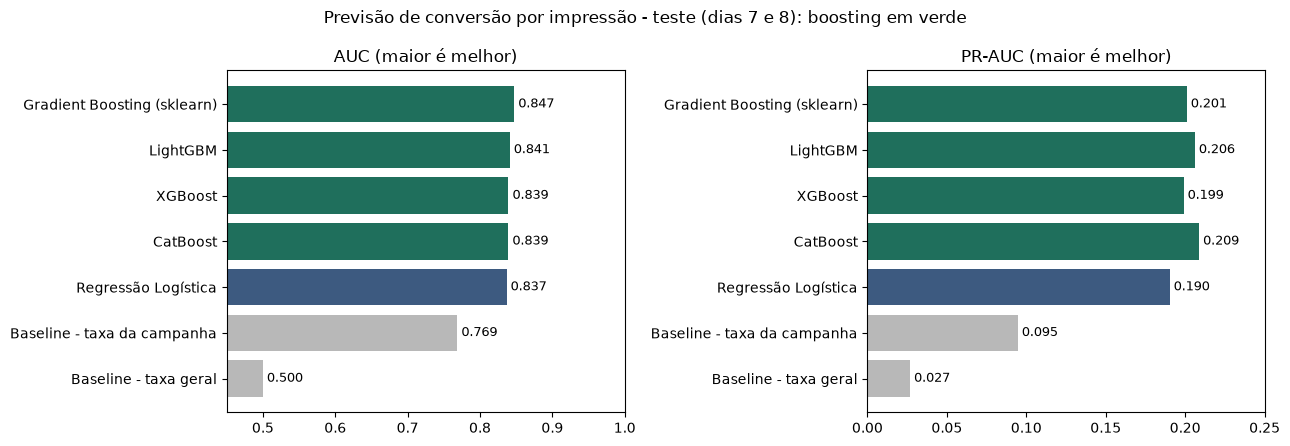

In [20]:
no_teste = comparacao[comparacao["conjunto"].str.startswith("teste")].sort_values("AUC")
cores = ["#b8b8b8" if m.startswith("Baseline") else "#3d5a80" if "Logística" in m else "#1f6f5c"
         for m in no_teste["modelo"]]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for eixo, metrica, titulo in [(eixos[0], "AUC", "AUC (maior é melhor)"),
                              (eixos[1], "PR_AUC", "PR-AUC (maior é melhor)")]:
    eixo.barh(no_teste["modelo"], no_teste[metrica], color=cores)
    for y_pos, valor in enumerate(no_teste[metrica]):
        eixo.text(valor, y_pos, f" {valor:.3f}", va="center", fontsize=9)
    eixo.set_title(titulo)
eixos[0].set_xlim(0.45, 1)
eixos[1].set_xlim(0, no_teste["PR_AUC"].max() * 1.2)
fig.suptitle("Previsão de conversão por impressão - teste (dias 7 e 8): boosting em verde")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "criteo_comparacao_modelos.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: calibração (a probabilidade prevista bate com a real?)

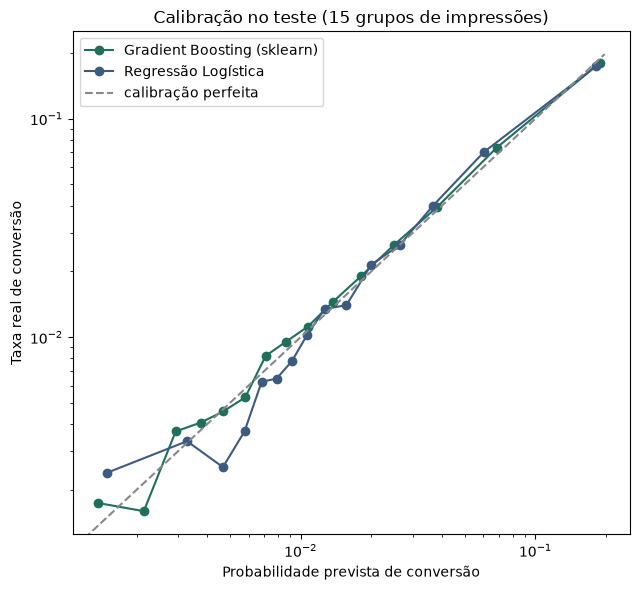

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for nome, cor in [(MELHOR, "#1f6f5c"), ("Regressão Logística", "#3d5a80")]:
    real, previsto = calibration_curve(y_teste, previsoes_teste[nome], n_bins=15, strategy="quantile")
    ax.plot(previsto, real, marker="o", color=cor, label=nome)
limite = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, limite], [0, limite], linestyle="--", color="#888", label="calibração perfeita")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Probabilidade prevista de conversão")
ax.set_ylabel("Taxa real de conversão")
ax.set_title("Calibração no teste (15 grupos de impressões)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "criteo_calibracao.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: importância das variáveis

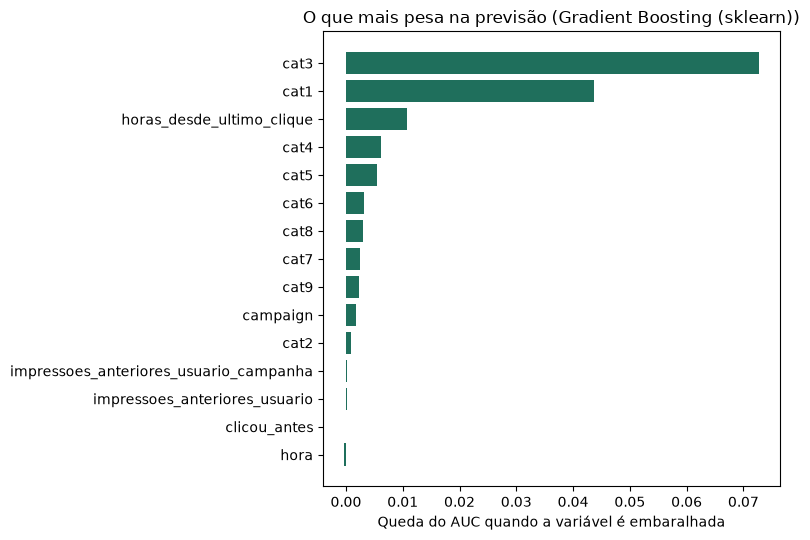

In [22]:
ordem = importancia.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(ordem["variavel"], ordem["queda_AUC"], color="#1f6f5c")
ax.set_xlabel("Queda do AUC quando a variável é embaralhada")
ax.set_title(f"O que mais pesa na previsão ({MELHOR})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "criteo_importancia_variaveis.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: shap (se instalado e o melhor modelo for xgboost, lightgbm ou catboost)

In [23]:
if shap is not None and MELHOR in ("XGBoost", "LightGBM", "CatBoost"):
    try:
        amostra_shap = teste.sample(5_000, random_state=SEMENTE)
        X_shap = amostra_shap[VARIAVEIS] if MELHOR == "CatBoost" else como_categoria(amostra_shap)
        explicador = shap.TreeExplainer(modelos_boosting[MELHOR])
        valores = explicador.shap_values(X_shap)
        if isinstance(valores, list):
            valores = valores[1]
        shap.summary_plot(valores, X_shap, show=False, plot_type="bar")
        plt.title(f"SHAP - contribuição média de cada variável ({MELHOR})")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "criteo_shap.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close()
    except Exception as erro:
        print("SHAP falhou e foi pulado:", erro)
else:
    print("SHAP pulado: precisa do shap instalado e de XGBoost, LightGBM ou CatBoost como melhor modelo.")

SHAP pulado: precisa do shap instalado e de XGBoost, LightGBM ou CatBoost como melhor modelo.


## Gráfico: curva de custo x conversões

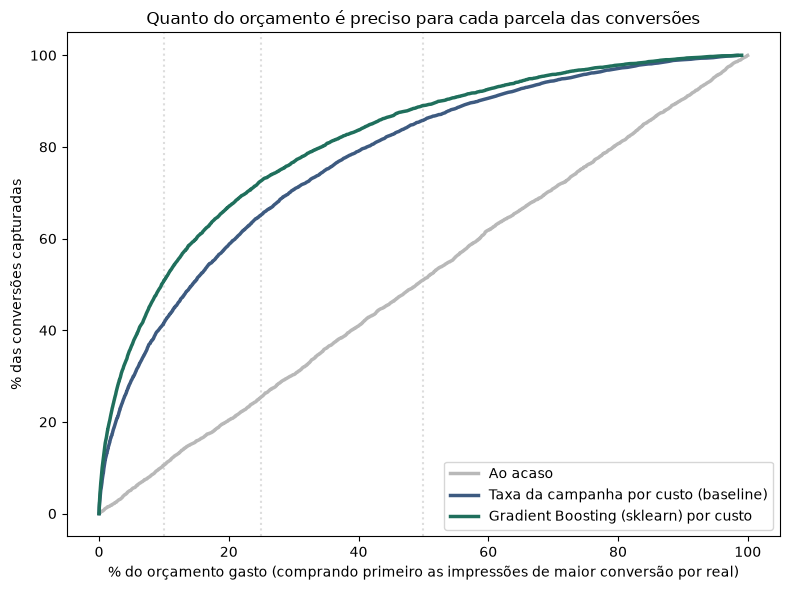

In [24]:
fig, ax = plt.subplots(figsize=(8, 6))
for (nome, score), cor in zip(estrategias.items(), ["#b8b8b8", "#3d5a80", "#1f6f5c"]):
    frac_custo_e, frac_conv_e, _, _ = curva(score)
    passo = max(1, len(frac_custo_e) // 2000)
    ax.plot(frac_custo_e[::passo] * 100, frac_conv_e[::passo] * 100, color=cor, linewidth=2.5, label=nome)
for parte in [10, 25, 50]:
    ax.axvline(parte, color="#ddd", linestyle=":", zorder=0)
ax.set_xlabel("% do orçamento gasto (comprando primeiro as impressões de maior conversão por real)")
ax.set_ylabel("% das conversões capturadas")
ax.set_title("Quanto do orçamento é preciso para cada parcela das conversões")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "criteo_curva_custo_conversoes.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Conclusão

In [25]:
teste_m = comparacao[comparacao["conjunto"].str.startswith("teste")].set_index("modelo")
melhor_m = teste_m.loc[MELHOR]
campanha_m = teste_m.loc["Baseline - taxa da campanha"]
logistica_m = teste_m.loc["Regressão Logística"]
r = resumo_orcamento.set_index("estrategia")
custo_50 = faixas.loc[faixas["orcamento_usado"] == "50%"].iloc[0]
custo_100 = faixas.loc[faixas["orcamento_usado"] == "100%"].iloc[0]

print("\n============================")
print("CONCLUSÃO - CRITEO COM BOOSTING")
print("============================")
print(
    f"1) {MELHOR}: AUC de {melhor_m['AUC']:.3f} no teste, contra {campanha_m['AUC']:.3f} da taxa da "
    f"campanha e {logistica_m['AUC']:.3f} da Regressão Logística. Na PR-AUC (mais exigente com "
    f"conversões raras): {melhor_m['PR_AUC']:.3f} contra {campanha_m['PR_AUC']:.3f} e {logistica_m['PR_AUC']:.3f}."
)
print(
    f"2) Onde gastar: comprando primeiro as impressões de maior conversão prevista por real, "
    f"10% do orçamento captura {r.loc[f'{MELHOR} por custo', 'conversoes_com_10%_do_custo']:.0%} das "
    f"conversões (ao acaso: 10%; pela taxa da campanha: "
    f"{r.loc['Taxa da campanha por custo (baseline)', 'conversoes_com_10%_do_custo']:.0%})."
)
print(
    f"3) Custo médio x incremental: até 50% do orçamento, a conversão custa em média "
    f"{custo_50['custo_medio_relativo']:.2f}x o custo médio geral; a última faixa (90% a 100%) custa "
    f"{custo_100['custo_incremental_relativo']:.1f}x por conversão. O custo médio esconde que as "
    "últimas impressões compradas quase não convertem - a mesma lógica do slide do projeto."
)
print(
    "\nCuidado de leitura: o modelo ordena impressões por chance de conversão; isso não prova que "
    "o anúncio CAUSOU a conversão (parte dos usuários converteria de qualquer jeito). Para medir o "
    "efeito causal da mídia, a ferramenta é o teste geográfico do outro notebook."
)


CONCLUSÃO - CRITEO COM BOOSTING
1) Gradient Boosting (sklearn): AUC de 0.847 no teste, contra 0.769 da taxa da campanha e 0.837 da Regressão Logística. Na PR-AUC (mais exigente com conversões raras): 0.201 contra 0.095 e 0.190.
2) Onde gastar: comprando primeiro as impressões de maior conversão prevista por real, 10% do orçamento captura 51% das conversões (ao acaso: 10%; pela taxa da campanha: 42%).
3) Custo médio x incremental: até 50% do orçamento, a conversão custa em média 0.56x o custo médio geral; a última faixa (90% a 100%) custa 13.8x por conversão. O custo médio esconde que as últimas impressões compradas quase não convertem - a mesma lógica do slide do projeto.

Cuidado de leitura: o modelo ordena impressões por chance de conversão; isso não prova que o anúncio CAUSOU a conversão (parte dos usuários converteria de qualquer jeito). Para medir o efeito causal da mídia, a ferramenta é o teste geográfico do outro notebook.
